In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
import shutil
import warnings 
warnings.filterwarnings('ignore')
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import losses
from tensorflow.keras import callbacks
from tensorflow.keras import layers
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.layers import Conv2D, MaxPooling2D , GlobalAveragePooling2D,Dropout,BatchNormalization,Input,Flatten,Dense
from tensorflow.keras.applications import EfficientNetB0,ResNet50, MobileNetV2

# Load The Data

In [2]:
dataset_path = Path("/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset")

for split in ['Training', 'Testing']:
    print(f"\n{split}:")
    for cls in sorted((dataset_path / split).iterdir()):
        if cls.is_dir():
            n = len(list(cls.glob("*.*")))
            print(f"  {cls.name:<20} {n} images")


Training:
  glioma               1400 images
  meningioma           1400 images
  notumor              1400 images
  pituitary            1400 images

Testing:
  glioma               400 images
  meningioma           400 images
  notumor              400 images
  pituitary            400 images


In [3]:
dataset_path = Path("/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset")
train_path   = dataset_path / "Training"
test_path    = dataset_path / "Testing"

class_names = sorted([d.name for d in train_path.iterdir() if d.is_dir()])
NUM_CLASSES  = len(class_names)
print(f"Classes: {class_names}")

IMG_SIZE = (224, 224)
BATCH    = 32
AUTOTUNE = tf.data.AUTOTUNE

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


# Visualize Sample Images

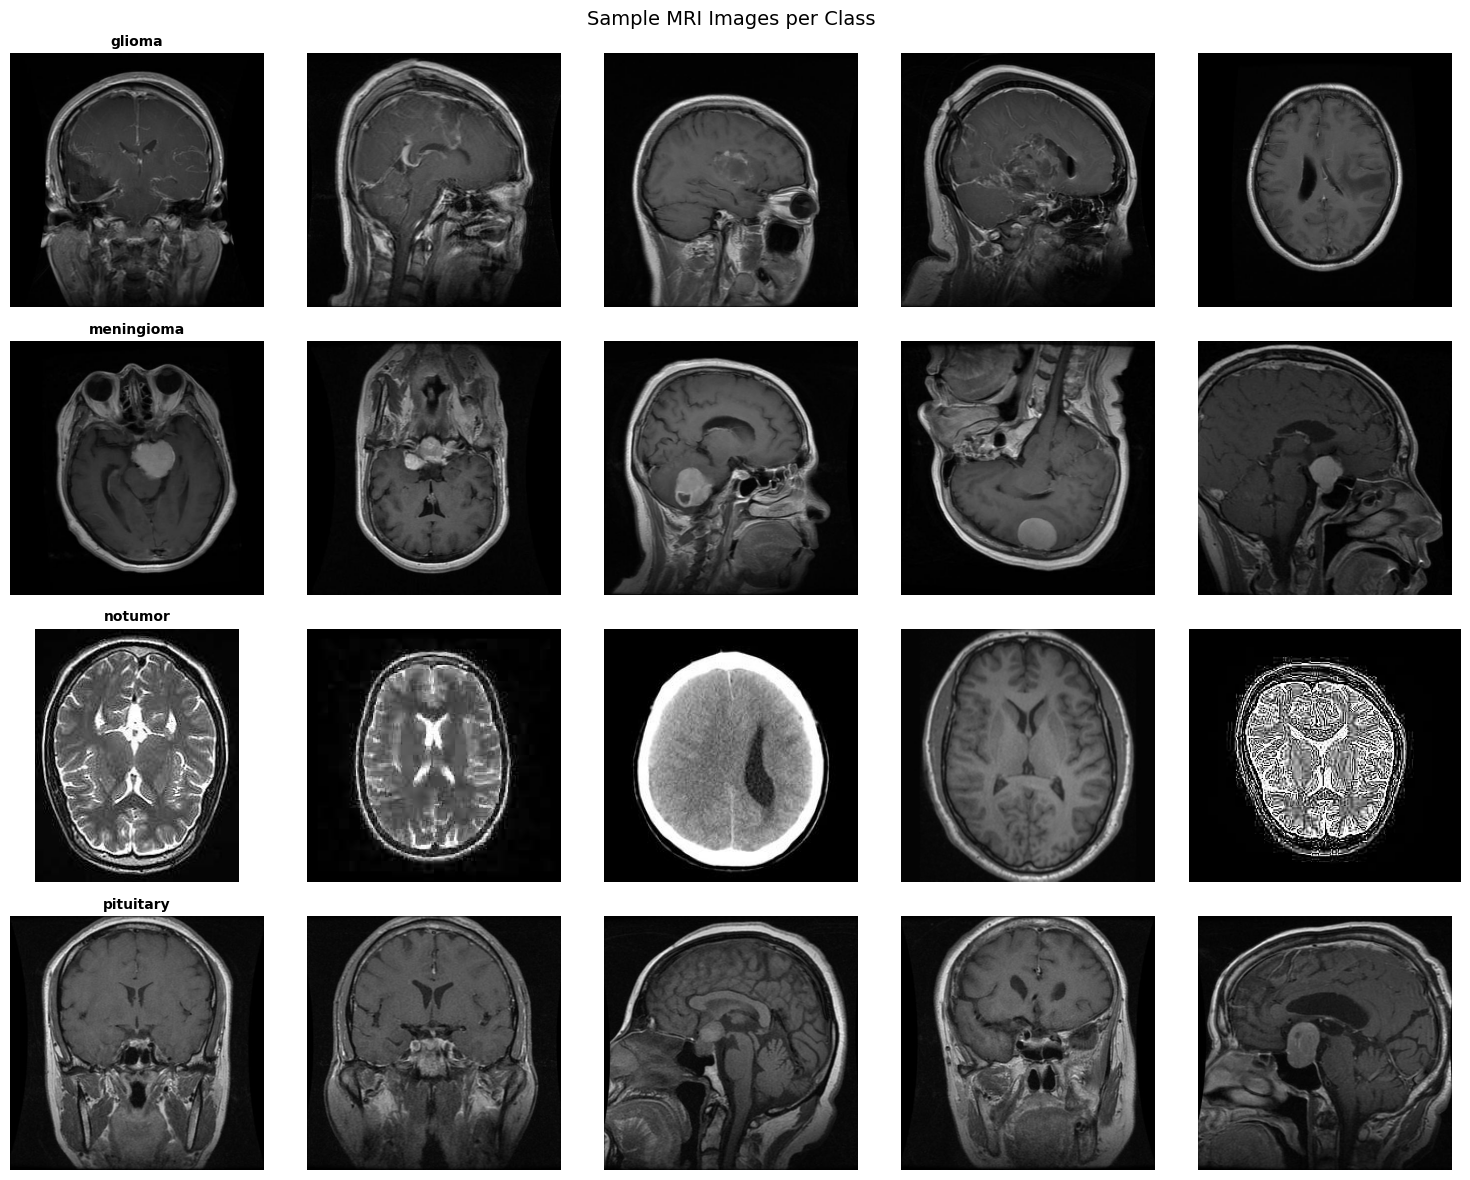

In [4]:
def show_sample_images(data_path, class_names, n_samples=5):
    fig, axes = plt.subplots(len(class_names), n_samples,
                              figsize=(n_samples * 3, len(class_names) * 3))
    for i, cls in enumerate(class_names):
        images = list((data_path / cls).glob("*.*"))[:n_samples]
        for j, img_path in enumerate(images):
            img = Image.open(img_path).convert("RGB")
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')
            if j == 0:
                axes[i, j].set_title(cls, fontsize=10, fontweight='bold')
    plt.suptitle("Sample MRI Images per Class", fontsize=14)
    plt.tight_layout()
    plt.show()

show_sample_images(train_path, class_names)

# Splitting the Data and Data Augmentation

In [5]:
from sklearn.model_selection import train_test_split

all_images, all_labels = [], []
for cls in class_names:
    for img_path in (train_path / cls).glob("*.*"):
        all_images.append(str(img_path))
        all_labels.append(cls)

X_train, X_val, y_train, y_val = train_test_split(
    all_images, all_labels,
    test_size=0.15, stratify=all_labels, random_state=42
)

print(f"Train: {len(X_train)} | Val: {len(X_val)}")

split_path = Path("/kaggle/working/split")

def copy_to_split(paths, labels, split_name):
    for path, label in zip(paths, labels):
        dest = split_path / split_name / label
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy(path, dest / Path(path).name)

copy_to_split(X_train, y_train, "train")
copy_to_split(X_val,   y_val,   "val")
print("Done copying.")

Train: 4760 | Val: 840
Done copying.


In [6]:
# ── Load datasets ────────────────────────────────────────────
train_ds = image_dataset_from_directory(
    split_path / "train",
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=True, seed=42
)
val_ds = image_dataset_from_directory(
    split_path / "val",
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=False
)
test_ds = image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=False
)

# ── Augmentation & rescaling ─────────────────────────────────
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
], name="augmentation")

rescaling = layers.Rescaling(1./255)

def preprocess_train(x, y):
    x = rescaling(x)
    x = data_augmentation(x, training=True)
    return x, y

def preprocess_eval(x, y):
    return rescaling(x), y

# ── Apply preprocessing ONCE ─────────────────────────────────
train_ds = train_ds.map(preprocess_train, num_parallel_calls=AUTOTUNE)\
                   .shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.map(preprocess_eval,   num_parallel_calls=AUTOTUNE)\
                 .prefetch(AUTOTUNE)
test_ds  = test_ds.map(preprocess_eval,  num_parallel_calls=AUTOTUNE)\
                  .prefetch(AUTOTUNE)

# ── Sanity check ─────────────────────────────────────────────
print("Class distribution in val:")
val_labels = np.concatenate([y.numpy().argmax(axis=1) for _, y in val_ds])
unique, counts = np.unique(val_labels, return_counts=True)
for idx, count in zip(unique, counts):
    print(f"  {class_names[idx]}: {count}")

print(f"\nTrain batches : {len(train_ds)}")
print(f"Val batches   : {len(val_ds)}")
print(f"Test batches  : {len(test_ds)}")

Found 4760 files belonging to 4 classes.


I0000 00:00:1792962134.723049      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792962134.726773      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 840 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Class distribution in val:
  glioma: 210
  meningioma: 210
  notumor: 210
  pituitary: 210

Train batches : 149
Val batches   : 27
Test batches  : 50


# Build Custom CNN

In [7]:
def build_custom_cnn(input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    model = Sequential([
        Input(shape=input_shape),

        Conv2D(32, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        Conv2D(32, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2), Dropout(0.25),

        Conv2D(64, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        Conv2D(64, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2), Dropout(0.25),

        Conv2D(128, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        Conv2D(128, (3,3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D(2), Dropout(0.25),

        GlobalAveragePooling2D(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name="custom_cnn")
    return model

# Callbacks & Compile

In [8]:
def get_callbacks(model_name):
    return [
        callbacks.EarlyStopping(
            monitor='val_accuracy', patience=10,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=5, min_lr=1e-7, verbose=1
        ),
        callbacks.ModelCheckpoint(
            f"{model_name}_best.keras",
            monitor='val_accuracy',
            save_best_only=True, verbose=1
        )
    ]

def compile_model(model, lr=1e-3, label_smoothing=0.0):
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss=losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=['accuracy']
    )

In [9]:
cnn_model = build_custom_cnn()
compile_model(cnn_model, lr=1e-3, label_smoothing=0.0)
cnn_history = cnn_model.fit(train_ds,validation_data=val_ds,epochs=50,callbacks=get_callbacks("custom_cnn"))

Epoch 1/50


2026-10-25 21:02:42.074659: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:02:42.228532: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:02:45.068942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:02:45.351348: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/149 ━━━━━━━━━━━━━━━━━━━━ 1:28:17 36s/step - accuracy: 0.1562 - loss: 1.8498

I0000 00:00:1792962174.314982      75 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 31/149 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.5079 - loss: 1.2745

2026-10-25 21:03:02.326196: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:03:02.478258: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:03:04.712828: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:03:05.000214: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.6050 - loss: 1.0704
Epoch 1: val_accuracy improved from None to 0.25000, saving model to custom_cnn_best.keras

Epoch 1: finished saving model to custom_cnn_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 76s 272ms/step - accuracy: 0.6649 - loss: 0.9337 - val_accuracy: 0.2500 - val_loss: 2.9702 - learning_rate: 0.0010
Epoch 2/50
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7205 - loss: 0.7398
Epoch 2: val_accuracy improved from 0.25000 to 0.25119, saving model to custom_cnn_best.keras

Epoch 2: finished saving model to custom_cnn_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 35s 145ms/step - accuracy: 0.7321 - loss: 0.7187 - val_accuracy: 0.2512 - val_loss: 4.1321 - learning_rate: 0.0010
Epoch 3/50
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.7861 - loss: 0.5835
Epoch 3: val_accuracy improved from 0.25119 to 0.25357, saving model to custom_cnn_best.keras

Epoch 3: finished saving model to custom_cnn_best.keras
149/149 ━

# EfficientNetb0

In [10]:
def preprocess_train_raw(x, y):
    x = data_augmentation(x, training=True)
    return x, y

def preprocess_eval_raw(x, y):
    return x, y

In [11]:
train_ds_raw = image_dataset_from_directory(
    split_path / "train",
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=True, seed=42
)
val_ds_raw = image_dataset_from_directory(
    split_path / "val",
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=False
)
test_ds_raw = image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode='categorical',
    shuffle=False
)

train_ds_raw = train_ds_raw.map(preprocess_train_raw, num_parallel_calls=AUTOTUNE)\
                           .shuffle(1000).prefetch(AUTOTUNE)
val_ds_raw   = val_ds_raw.map(preprocess_eval_raw,   num_parallel_calls=AUTOTUNE)\
                         .prefetch(AUTOTUNE)
test_ds_raw  = test_ds_raw.map(preprocess_eval_raw,  num_parallel_calls=AUTOTUNE)\
                          .prefetch(AUTOTUNE)

Found 4760 files belonging to 4 classes.
Found 840 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


In [12]:
def build_efficientnet(num_classes=NUM_CLASSES):
    base = EfficientNetB0(weights='imagenet', include_top=False,
                          input_shape=(224, 224, 3))
    base.trainable = False
    model = Sequential([
        base,
        GlobalAveragePooling2D(),
        BatchNormalization(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name="efficientnet_b0")
    return model, base

In [13]:
eff_model, eff_base = build_efficientnet()
compile_model(eff_model, lr=1e-3, label_smoothing=0.0)
eff_history_1 = eff_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=20, callbacks=get_callbacks("eff_phase1"))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20


2026-10-25 21:33:08.136998: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:08.279922: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:08.626738: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:08.768360: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:09.550585: E external/local_xla/xla/stream_

  5/149 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.3861 - loss: 1.9887

2026-10-25 21:33:23.677635: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:23.818501: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:24.155542: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:24.297377: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:25.058316: E external/local_xla/xla/stream_

148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7124 - loss: 0.9681

2026-10-25 21:33:48.789472: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:48.925506: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:49.236604: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:49.378455: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 21:33:50.134194: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.85000, saving model to eff_phase1_best.keras

Epoch 1: finished saving model to eff_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 77s 256ms/step - accuracy: 0.7870 - loss: 0.6854 - val_accuracy: 0.8500 - val_loss: 0.3944 - learning_rate: 0.0010
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8503 - loss: 0.4108
Epoch 2: val_accuracy improved from 0.85000 to 0.88333, saving model to eff_phase1_best.keras

Epoch 2: finished saving model to eff_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 45ms/step - accuracy: 0.8532 - loss: 0.4013 - val_accuracy: 0.8833 - val_loss: 0.2870 - learning_rate: 0.0010
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8840 - loss: 0.3199
Epoch 3: val_accuracy improved from 0.88333 to 0.91310, saving model to eff_phase1_best.keras

Epoch 3: finished saving model to eff_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.8832 - loss: 0.3286 - val_accur

In [14]:
eff_base.trainable = True
for layer in eff_base.layers[:-30]:
    layer.trainable = False
compile_model(eff_model, lr=1e-5, label_smoothing=0.0)
eff_history_2 = eff_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=30, callbacks=get_callbacks("eff_finetune"))

Epoch 1/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.8271 - loss: 0.4647
Epoch 1: val_accuracy improved from None to 0.91667, saving model to eff_finetune_best.keras

Epoch 1: finished saving model to eff_finetune_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 71s 216ms/step - accuracy: 0.8441 - loss: 0.4145 - val_accuracy: 0.9167 - val_loss: 0.2202 - learning_rate: 1.0000e-05
Epoch 2/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8675 - loss: 0.3492
Epoch 2: val_accuracy did not improve from 0.91667
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.8809 - loss: 0.3207 - val_accuracy: 0.8952 - val_loss: 0.2688 - learning_rate: 1.0000e-05
Epoch 3/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8850 - loss: 0.3030
Epoch 3: val_accuracy did not improve from 0.91667
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.8914 - loss: 0.2869 - val_accuracy: 0.8940 - val_loss: 0.2718 - learning_rate: 1.0000e-05
Epoch 4/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s

# ResNet50

In [15]:
def build_resnet50(num_classes=NUM_CLASSES):
    base = ResNet50(weights='imagenet', include_top=False,
                    input_shape=(224, 224, 3))
    base.trainable = False
    model = Sequential([
        base,
        GlobalAveragePooling2D(),
        BatchNormalization(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name="resnet50")
    return model, base


In [16]:
res_model, res_base = build_resnet50()
compile_model(res_model, lr=1e-3, label_smoothing=0.0)
res_history_1 = res_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=20, callbacks=get_callbacks("res_phase1"))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7368 - loss: 0.8678
Epoch 1: val_accuracy improved from None to 0.86429, saving model to res_phase1_best.keras

Epoch 1: finished saving model to res_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 55s 195ms/step - accuracy: 0.8145 - loss: 0.6410 - val_accuracy: 0.8643 - val_loss: 0.3448 - learning_rate: 0.0010
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8844 - loss: 0.3557
Epoch 2: val_accuracy improved from 0.86429 to 0.91548, saving model to res_phase1_best.keras

Epoch 2: finished saving model to res_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 28s 104ms/step - accuracy: 0.8861 - loss: 0.3572 - val_accuracy: 0.9155 - val_loss: 0.2403 - learning_rate: 0.0010
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9043 - loss: 0.3064
Epoch 3: val_accuracy improved from 0.91548 to 0.91905, saving model to res_phase1_best.keras

Epoch

In [17]:
res_base.trainable = True
for layer in res_base.layers[:-30]:
    layer.trainable = False
compile_model(res_model, lr=1e-5, label_smoothing=0.0)
res_history_2 = res_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=30, callbacks=get_callbacks("res_finetune"))

Epoch 1/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9401 - loss: 0.1525
Epoch 1: val_accuracy improved from None to 0.93452, saving model to res_finetune_best.keras

Epoch 1: finished saving model to res_finetune_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 67s 239ms/step - accuracy: 0.9456 - loss: 0.1463 - val_accuracy: 0.9345 - val_loss: 0.2143 - learning_rate: 1.0000e-05
Epoch 2/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9588 - loss: 0.1174
Epoch 2: val_accuracy improved from 0.93452 to 0.94405, saving model to res_finetune_best.keras

Epoch 2: finished saving model to res_finetune_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 34s 141ms/step - accuracy: 0.9618 - loss: 0.1010 - val_accuracy: 0.9440 - val_loss: 0.1820 - learning_rate: 1.0000e-05
Epoch 3/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.9609 - loss: 0.1017
Epoch 3: val_accuracy did not improve from 0.94405
149/149 ━━━━━━━━━━━━━━━━━━━━ 34s 143ms/step - accuracy: 0.9609 - loss: 0.1045 - va

# MobileNetV2

In [18]:
def build_mobilenet(num_classes=NUM_CLASSES):
    base = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base.trainable = False

    model = Sequential([
        base,
        GlobalAveragePooling2D(),
        BatchNormalization(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name="mobilenet_v2")

    return model, base

In [19]:
mob_model, mob_base = build_mobilenet()
mob_model.summary()
compile_model(mob_model, lr=1e-3, label_smoothing=0.0)
mob_history_1 = mob_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=20, callbacks=get_callbacks("mob_phase1"))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenet_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,068 (9.89 MB)

 Trainable params: 331,524 (1.26 MB)

...

145/149 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6869 - loss: 0.9362

2026-10-25 22:18:59.802130: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 22:18:59.959056: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 22:19:00.095560: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6884 - loss: 0.9320

2026-10-25 22:19:14.409240: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-25 22:19:14.554988: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.82619, saving model to mob_phase1_best.keras

Epoch 1: finished saving model to mob_phase1_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 187ms/step - accuracy: 0.7613 - loss: 0.7291 - val_accuracy: 0.8262 - val_loss: 0.4426 - learning_rate: 0.0010
Epoch 2/20
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8133 - loss: 0.5395
Epoch 2: val_accuracy did not improve from 0.82619
149/149 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.8254 - loss: 0.5123 - val_accuracy: 0.7905 - val_loss: 0.5060 - learning_rate: 0.0010
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8478 - loss: 0.4302
Epoch 3: val_accuracy did not improve from 0.82619
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.8445 - loss: 0.4285 - val_accuracy: 0.8119 - val_loss: 0.4775 - learning_rate: 0.0010
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8600 - loss: 0.3774
Epoch 4: val_accuracy did not improve from 0.82619
149/149

In [20]:
mob_base.trainable = True
for layer in mob_base.layers[:-30]:
    layer.trainable = False
compile_model(mob_model, lr=1e-5, label_smoothing=0.0)
mob_history_2 = mob_model.fit(train_ds_raw, validation_data=val_ds_raw,epochs=30, callbacks=get_callbacks("mob_finetune"))

Epoch 1/30
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.6999 - loss: 0.8599
Epoch 1: val_accuracy improved from None to 0.79405, saving model to mob_finetune_best.keras

Epoch 1: finished saving model to mob_finetune_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 53s 157ms/step - accuracy: 0.7437 - loss: 0.7108 - val_accuracy: 0.7940 - val_loss: 0.6752 - learning_rate: 1.0000e-05
Epoch 2/30
148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8254 - loss: 0.4670
Epoch 2: val_accuracy improved from 0.79405 to 0.81429, saving model to mob_finetune_best.keras

Epoch 2: finished saving model to mob_finetune_best.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.8263 - loss: 0.4720 - val_accuracy: 0.8143 - val_loss: 0.6284 - learning_rate: 1.0000e-05
Epoch 3/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8426 - loss: 0.4032
Epoch 3: val_accuracy did not improve from 0.81429
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.8410 - loss: 0.4050 - val_acc

# Models Evaluation


  Custom CNN  |  Test Accuracy: 0.9106
              precision    recall  f1-score   support

      glioma       0.95      0.81      0.87       400
  meningioma       0.95      0.84      0.89       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.90      1.00      0.95       400

    accuracy                           0.91      1600
   macro avg       0.92      0.91      0.91      1600
weighted avg       0.92      0.91      0.91      1600



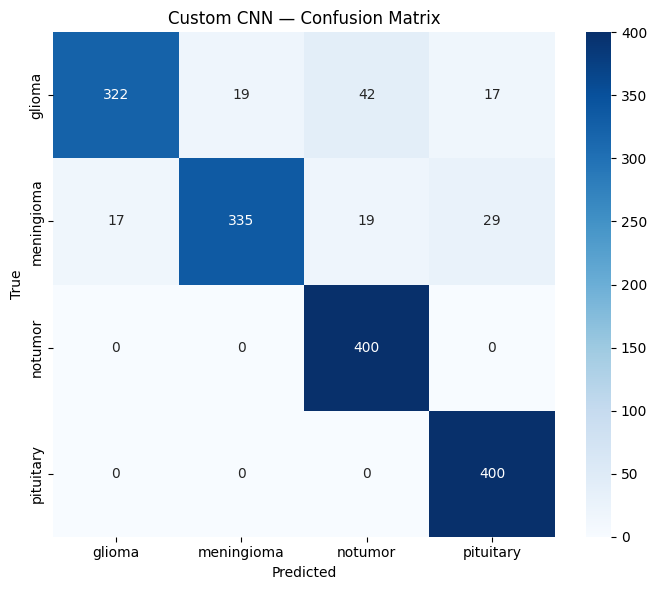

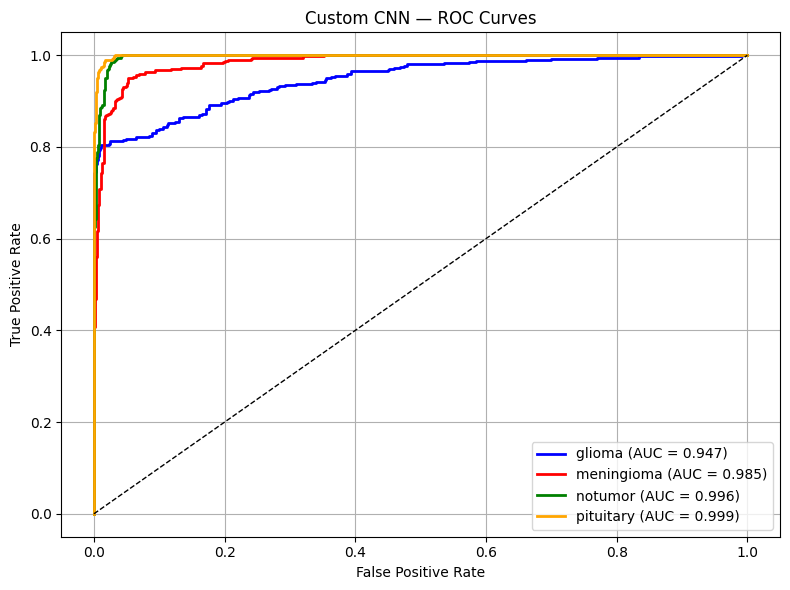


  EfficientNetB0  |  Test Accuracy: 0.9012
              precision    recall  f1-score   support

      glioma       0.93      0.77      0.84       400
  meningioma       0.87      0.85      0.86       400
     notumor       0.91      1.00      0.95       400
   pituitary       0.91      0.99      0.95       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.90      1600
weighted avg       0.90      0.90      0.90      1600



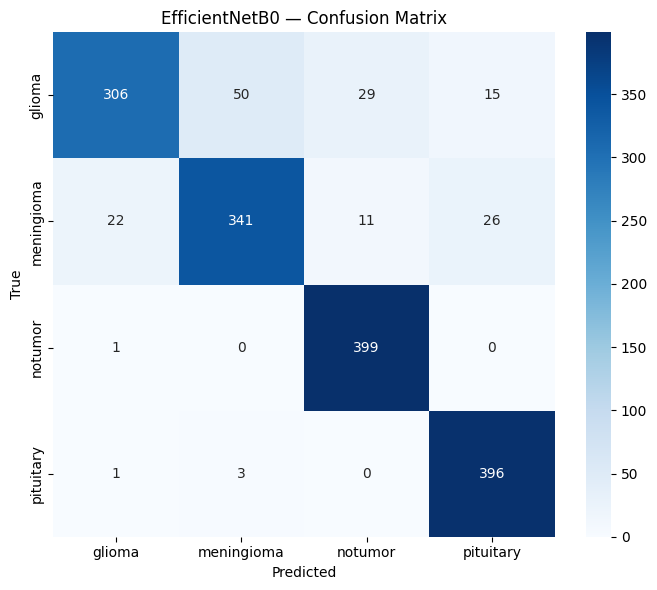

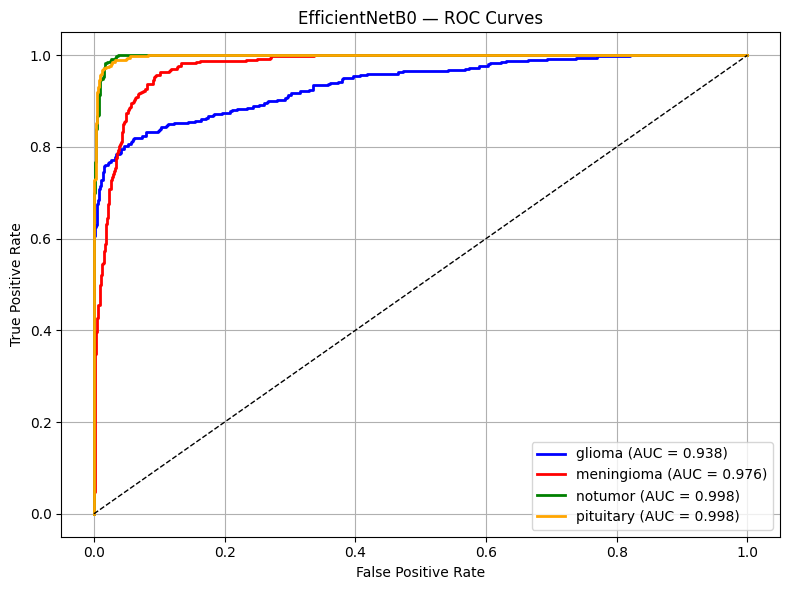


  ResNet50  |  Test Accuracy: 0.9431
              precision    recall  f1-score   support

      glioma       0.98      0.81      0.89       400
  meningioma       0.89      0.97      0.93       400
     notumor       0.92      1.00      0.96       400
   pituitary       0.99      0.99      0.99       400

    accuracy                           0.94      1600
   macro avg       0.95      0.94      0.94      1600
weighted avg       0.95      0.94      0.94      1600



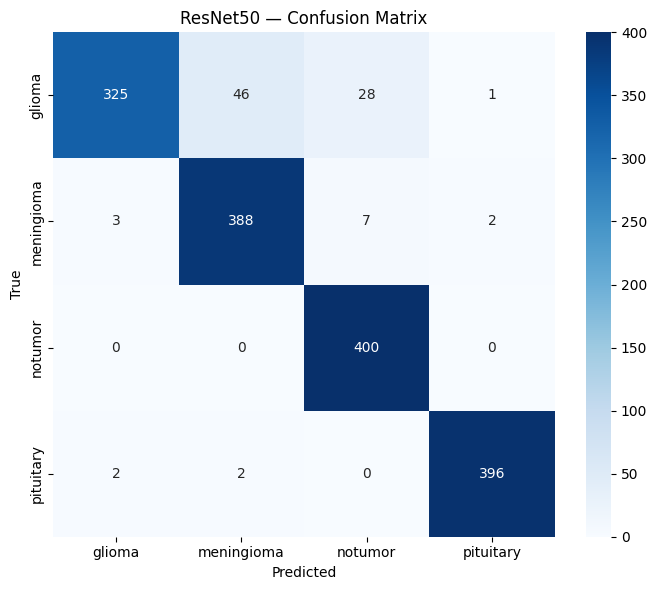

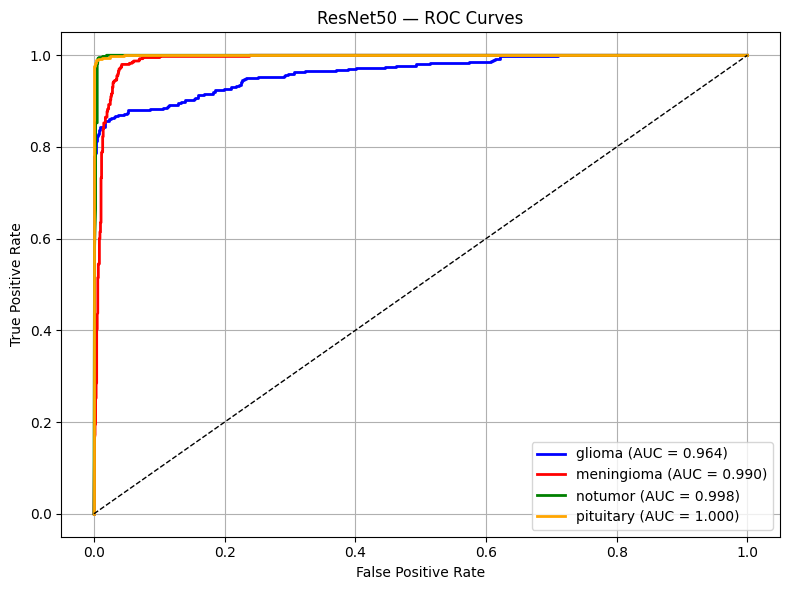


  MobileNetV2  |  Test Accuracy: 0.8169
              precision    recall  f1-score   support

      glioma       0.73      0.72      0.73       400
  meningioma       0.84      0.58      0.69       400
     notumor       0.82      1.00      0.90       400
   pituitary       0.88      0.96      0.92       400

    accuracy                           0.82      1600
   macro avg       0.82      0.82      0.81      1600
weighted avg       0.82      0.82      0.81      1600



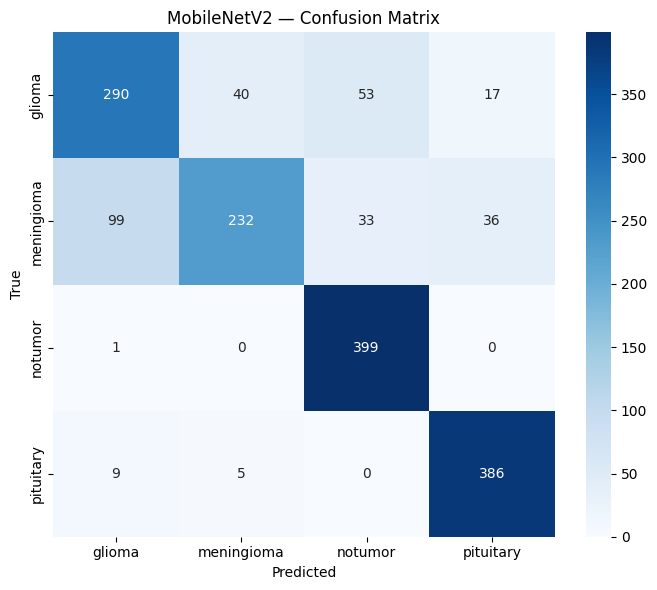

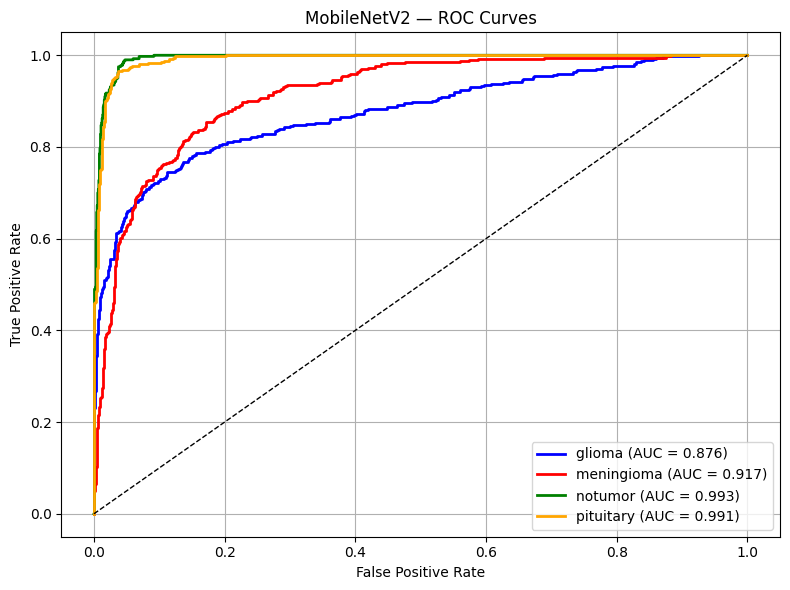

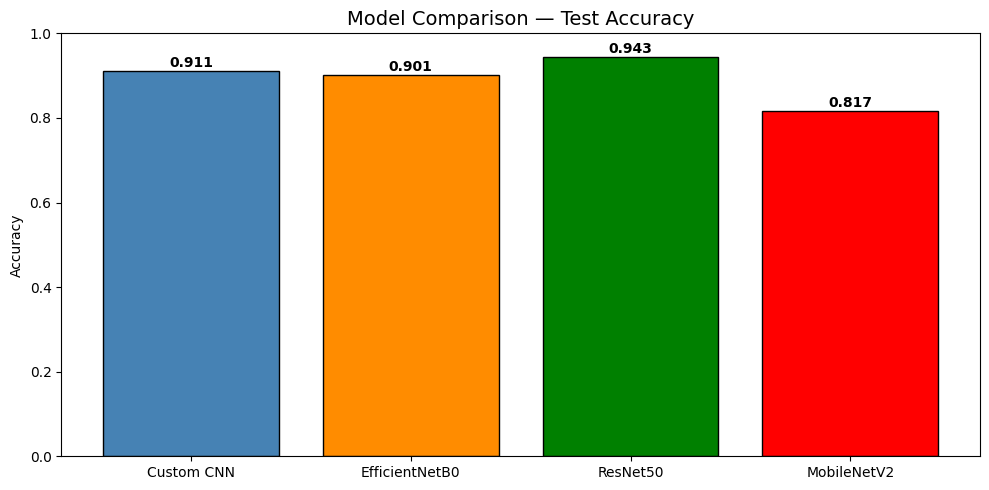

In [21]:
from sklearn.metrics import roc_curve, auc

def evaluate_model(model, model_name, test_ds, class_names):
    y_true_oh   = np.concatenate([y.numpy() for _, y in test_ds])
    y_true      = y_true_oh.argmax(axis=1)
    y_pred_prob = model.predict(test_ds, verbose=0)
    y_pred      = y_pred_prob.argmax(axis=1)

    acc = accuracy_score(y_true, y_pred)
    print(f"\n{'='*50}")
    print(f"  {model_name}  |  Test Accuracy: {acc:.4f}")
    print(f"{'='*50}")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} — Confusion Matrix")
    plt.ylabel("True"); plt.xlabel("Predicted")
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(8, 6))
    colors = ['blue', 'red', 'green', 'orange']
    for i, (cls, color) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_true_oh[:, i], y_pred_prob[:, i])
        roc_auc     = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2,
                 label=f"{cls} (AUC = {roc_auc:.3f})")
    plt.plot([0,1], [0,1], 'k--', lw=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} — ROC Curves")
    plt.legend(loc='lower right'); plt.grid(True)
    plt.tight_layout(); plt.show()

    return acc

results = {}
results['Custom CNN']     = evaluate_model(cnn_model, "Custom CNN",     test_ds,     class_names)
results['EfficientNetB0'] = evaluate_model(eff_model, "EfficientNetB0", test_ds_raw, class_names)
results['ResNet50']       = evaluate_model(res_model, "ResNet50",       test_ds_raw, class_names)
results['MobileNetV2']    = evaluate_model(mob_model, "MobileNetV2",    test_ds_raw, class_names)

plt.figure(figsize=(10, 5))
colors = ['steelblue', 'darkorange', 'green', 'red']
bars = plt.bar(results.keys(), results.values(),
               color=colors, edgecolor='black')
plt.ylim(0, 1)
plt.title("Model Comparison — Test Accuracy", fontsize=14)
plt.ylabel("Accuracy")
for bar, val in zip(bars, results.values()):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f"{val:.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Save the Best Model

In [22]:
res_model.save('/kaggle/working/resnet50_best.h5')
print("Model saved as H5")

Model saved as H5
